# 03 · Results

These are the results of `scripts/irt/run_experiment.py`.

- **5 family splits**: no validation or test model has a close relative in train.
- **20 seeds** per k: each seed picks a different set of k questions.
- The number of IRT dimensions **D** and the **gp-IRT weights** are chosen on validation. Test is evaluated once.

Methods compared, each seeing only k of a model's answers:
| method | estimate of the full MMLU score |
|---|---|
| random | accuracy on k random questions |
| stratified | accuracy on k random questions, spread over subjects in proportion to their size |
| IRT anchors | weighted accuracy on k representative questions chosen by clustering the IRT item parameters |
| p-IRT | infer the model's θ from its k answers and predict all the other questions |
| gp-IRT | a weighted blend of IRT anchors and p-IRT |

In [1]:
import sys

sys.path.insert(0, "../scripts/irt")  # for the efficbench loader

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from efficbench import load

from cabench.splits import behaviour_families, split_models

# One row per (split, D, k, method, seed) with that run's error metrics
validation = pd.read_csv("../results/irt/validation.csv")
test = pd.read_csv("../results/irt/test.csv")

# The gp-IRT blend weight fitted for each (split, D, k)
gp_weights = pd.read_csv("../results/irt/gp_weights.csv")

METHODS = ["random", "stratified", "IRT anchors", "p-IRT", "gp-IRT"]

## Are the splits fair?
For each held-out model, find its most similar training model. A "twin" is a training model whose answers correlate above 0.9.
The table shows what share of held-out models have one.

In [2]:
Y, _, _ = load()
families = behaviour_families(Y)

# Correlation between every pair of models, ignoring each model with itself
correlation = np.corrcoef(Y)
np.fill_diagonal(correlation, np.nan)


def share_with_twin(held_out, train):
    closest = np.nanmax(correlation[np.ix_(held_out, train)], axis=1)
    return f"{(closest > 0.9).mean():.0%}"


rows = []
for split in range(5):
    train, val, test_models = split_models(len(Y), split, groups=families)
    rows.append({
        "split": split,
        "train/val/test": f"{len(train)}/{len(val)}/{len(test_models)}",
        "val twins": share_with_twin(val, train),
        "test twins": share_with_twin(test_models, train),
    })

pd.DataFrame(rows).set_index("split")

,train/val/test,val twins,test twins
split,,,
0,303/60/65,0%,0%
1,300/64/64,0%,0%
2,303/60/65,0%,0%
3,293/71/64,0%,0%
4,300/82/46,0%,0%


## Choosing D (validation)
gp-IRT mean absolute error by k (rows) and D (columns), averaged over splits and seeds.
D is chosen by the lowest mean **log**-MAE across k, so the small errors at large k count as much as the big ones at small k.

In [3]:
gp_mae = validation[validation.method == "gp-IRT"].groupby(["D", "k"]).mae.mean().unstack("D")
display(gp_mae.map("{:.2%}".format))

np.log(gp_mae).mean().rename("mean log-MAE").round(3)

D,1,2,3,5
k,,,,
10,4.04%,3.89%,4.51%,4.79%
20,3.29%,3.12%,3.51%,3.97%
50,2.38%,2.20%,2.40%,2.76%
100,1.92%,1.80%,1.74%,1.95%
200,1.59%,1.45%,1.31%,1.35%
500,1.18%,1.10%,0.92%,0.96%


D
1   -3.815
2   -3.882
3   -3.876
5   -3.792
Name: mean log-MAE, dtype: float64

For reference, p-IRT on its own:

In [4]:
pirt_mae = validation[validation.method == "p-IRT"].groupby(["k", "D"]).mae.mean().unstack("D")
pirt_mae.map("{:.2%}".format)

D,1,2,3,5
k,,,,
10,4.06%,3.91%,4.50%,4.79%
20,3.32%,3.21%,3.51%,3.97%
50,2.46%,2.28%,2.43%,2.77%
100,2.06%,1.87%,1.77%,1.97%
200,1.81%,1.62%,1.36%,1.36%
500,1.70%,1.42%,1.00%,1.01%


## How much gp-IRT trusts the anchors
gp-IRT = weight × (IRT anchors) + (1 − weight) × (p-IRT). The weight is fitted per split and k on validation.

In [5]:
chosen_D = test.D.iloc[0]  # every test row stores the D picked on validation

weights = gp_weights[gp_weights.D == chosen_D]
weights.groupby("k").gp_weight.agg(["mean", "min", "max"]).round(2)

,mean,min,max
k,,,
10,0.02,0.00,0.11
20,0.07,0.00,0.28
50,0.08,0.00,0.30
100,0.11,0.00,0.36
200,0.22,0.03,0.53
500,0.43,0.22,0.70


## Test results
First average over the 20 seeds within each split, then take the mean ± SD across the 5 splits.

**Mean absolute error** of the predicted MMLU score (lower is better):

In [6]:
per_split = test.groupby(["method", "k", "split"])[["mae", "spearman"]].mean()
summary = per_split.groupby(["method", "k"]).agg(["mean", "std"])


def mean_plus_minus_sd(metric, number_format):
    """Table of "mean ± sd" strings: one row per k, one column per method."""
    mean = summary[metric]["mean"].map(number_format.format)
    sd = summary[metric]["std"].map(number_format.format)
    return (mean + " ± " + sd).unstack("method")[METHODS]


mean_plus_minus_sd("mae", "{:.2%}")

method,random,stratified,IRT anchors,p-IRT,gp-IRT
k,,,,,
10,12.32% ± 0.20%,13.18% ± 0.74%,10.73% ± 0.51%,5.56% ± 1.09%,5.60% ± 1.06%
20,8.47% ± 0.26%,8.14% ± 0.20%,7.46% ± 0.54%,4.34% ± 0.66%,4.32% ± 0.63%
50,5.18% ± 0.21%,5.57% ± 0.04%,4.62% ± 0.13%,2.89% ± 0.34%,2.86% ± 0.30%
100,3.96% ± 0.15%,3.68% ± 0.10%,3.45% ± 0.09%,2.38% ± 0.31%,2.31% ± 0.26%
200,2.52% ± 0.12%,2.46% ± 0.11%,2.36% ± 0.19%,1.96% ± 0.31%,1.77% ± 0.27%
500,1.77% ± 0.06%,1.55% ± 0.08%,1.53% ± 0.10%,1.71% ± 0.41%,1.29% ± 0.25%


**Spearman rank correlation** between predicted and true scores (1 = models ranked perfectly):

In [7]:
mean_plus_minus_sd("spearman", "{:.3f}")

method,random,stratified,IRT anchors,p-IRT,gp-IRT
k,,,,,
10,0.662 ± 0.063,0.664 ± 0.080,0.577 ± 0.075,0.762 ± 0.067,0.756 ± 0.066
20,0.736 ± 0.062,0.768 ± 0.065,0.741 ± 0.075,0.865 ± 0.022,0.867 ± 0.023
50,0.876 ± 0.047,0.876 ± 0.043,0.854 ± 0.062,0.927 ± 0.019,0.929 ± 0.020
100,0.916 ± 0.025,0.923 ± 0.028,0.903 ± 0.041,0.947 ± 0.012,0.950 ± 0.011
200,0.944 ± 0.024,0.947 ± 0.016,0.939 ± 0.025,0.962 ± 0.013,0.967 ± 0.008
500,0.973 ± 0.010,0.974 ± 0.010,0.969 ± 0.013,0.974 ± 0.008,0.981 ± 0.003


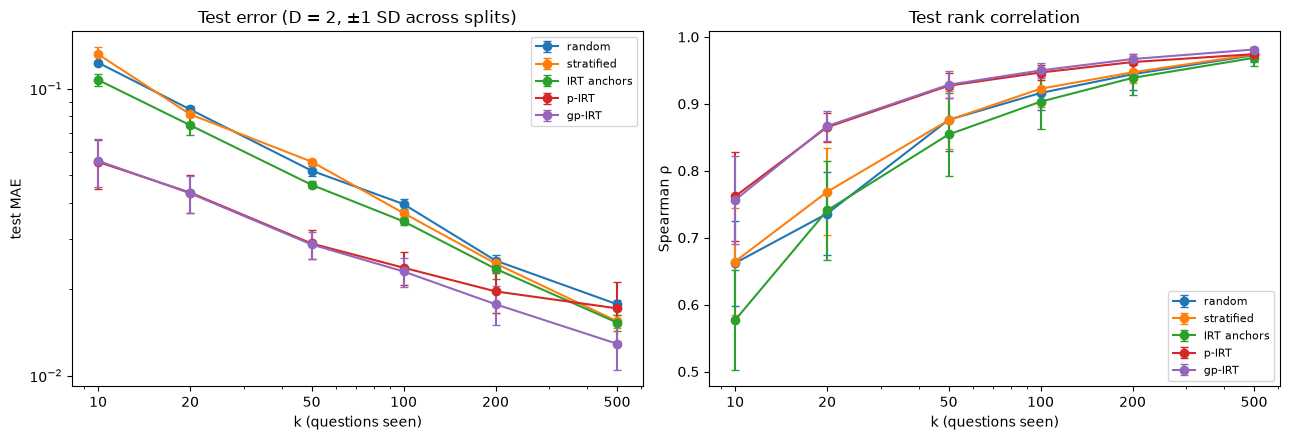

In [8]:
k_values = sorted(test.k.unique())

fig, (ax_mae, ax_rho) = plt.subplots(1, 2, figsize=(13, 4.5))

for method in METHODS:
    results = summary.loc[method]  # one row per k
    ax_mae.errorbar(results.index, results["mae"]["mean"], yerr=results["mae"]["std"],
                    marker="o", capsize=3, label=method)
    ax_rho.errorbar(results.index, results["spearman"]["mean"], yerr=results["spearman"]["std"],
                    marker="o", capsize=3, label=method)

ax_mae.set(xscale="log", yscale="log", xlabel="k (questions seen)", ylabel="test MAE",
           title=f"Test error (D = {chosen_D}, ±1 SD across splits)")
ax_rho.set(xscale="log", xlabel="k (questions seen)", ylabel="Spearman ρ",
           title="Test rank correlation")

for ax in (ax_mae, ax_rho):
    ax.set_xticks(k_values, k_values)
    ax.legend(fontsize=8)

plt.tight_layout()

## Bias
Average signed error: positive means the method **over**-estimates scores, negative means it **under**-estimates them.

In [9]:
test.groupby(["k", "method"]).bias.mean().unstack()[METHODS].map("{:+.2%}".format)

method,random,stratified,IRT anchors,p-IRT,gp-IRT
k,,,,,
10,-2.90%,+3.27%,-1.44%,+0.55%,+0.51%
20,+1.78%,+0.64%,-0.36%,+0.35%,+0.31%
50,-0.87%,+0.94%,+0.08%,+0.27%,+0.28%
100,-0.62%,-0.68%,+0.06%,+0.15%,+0.15%
200,-0.14%,+0.28%,+0.08%,+0.16%,+0.16%
500,-0.15%,-0.19%,+0.13%,+0.15%,+0.19%
